# Integration of SIMPLE on ccRCC metabolite dataset.

## 1. load packages

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import SIMPLE

# the location of R (used for the mclust clustering)
import os
os.environ['R_HOME'] = "/home/lvyz/miniconda3/envs/SIMPLE_env/lib/R"
os.environ['R_USER'] = "/home/lvyz/miniconda3/envs/SIMPLE_env/lib/python3.8/site-packages/rpy2"

import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
from sklearn.metrics import normalized_mutual_info_score as nmi
import torch

import matplotlib.pyplot as plt
import matplotlib as mpl
used_device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# font settings
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

# seed setting
seed=666
SIMPLE.utils.fix_randomseed(seed)

## 2. load data and construct spatial neighborhood graph

In [ ]:
slice_ids = ['R29_T','R51_T']
adata_all=[]
edge_index_list = []
offset = 0
num_nodes_per_slice = []
for slice_id in slice_ids:
    print(slice_id)
    adata=sc.read_h5ad(f"/Data/lvyz/data/SM_modal/{slice_id}_adata_SM_raw.h5ad")

    adata.obs_names = [x+'_'+slice_id for x in adata.obs_names]

    adata = SIMPLE.preprocess_metabolite(adata)
    
    SIMPLE.Cal_Spatial_Net(adata, k_cutoff=6)
    edge_index = adata.uns['edge_index']
    edge_index = edge_index + offset
    offset += adata.n_obs
    edge_index_list.append(edge_index)

    print(adata)
    adata_all.append(adata)

adata_concat = ad.concat(adata_all, label="batch", keys=slice_ids)
adata_concat.obs["batch"] = adata_concat.obs["batch"].astype('category')

# Concat the spatial neighborhood graph for multiple slices
edge_index_concat = np.hstack(edge_index_list)
adata_concat.uns['edge_index'] = edge_index_concat

# add metabolites annotations
mz_values = adata_concat.var_names.astype(float)
annot = pd.read_csv("/Data/lvyz/data/SM_modal/spatial_metabolites_annotation.csv")
annot["Metabolites"] = annot["Metabolites"].astype(str).str.replace('\n', '').str.strip()
annot_mz = annot["mz"].values
ppm_tol = 10
matched_metabolite = []
matched_mz = []
for mz in mz_values:
    ppm_diff = np.abs(annot_mz - mz) / annot_mz * 1e6  
    idx = np.where(ppm_diff <= ppm_tol)[0]
    if len(idx) > 0:
        best = idx[np.argmin(ppm_diff[idx])]
        matched_mz.append(annot_mz[best])
        matched_metabolite.append(annot.loc[best, "Metabolites"])
    else:
        matched_mz.append(np.nan)
        matched_metabolite.append(None)

adata_concat.var["matched_mz"] = matched_mz
adata_concat.var["metabolite_name"] = matched_metabolite
adata_concat.var['metabolite_name'] = adata_concat.var['metabolite_name'].str.replace('\n', '').str.replace(';', '_')
print(adata_concat.var[["matched_mz", "metabolite_name"]].head())
matched_count = adata_concat.var["metabolite_name"].notna().sum()
total = adata_concat.var.shape[0]

R29_T


------------Calculating spatial neighborhood graph------------
AnnData object with n_obs × n_vars = 26723 × 1297
    obs: 'x_coord_original', 'y_coord_original', 'total_intensity_pos', 'mean_intensity_pos', 'total_intensity_neg', 'mean_intensity_neg', 'spot_index'
    var: 'name', 'type', 'n_cells', 'min', 'max'
    uns: 'edge_index'
    obsm: 'spatial'
R51_T
------------Calculating spatial neighborhood graph------------
AnnData object with n_obs × n_vars = 17764 × 1274
    obs: 'x_coord_original', 'y_coord_original', 'total_intensity_pos', 'mean_intensity_pos', 'total_intensity_neg', 'mean_intensity_neg', 'spot_index'
    var: 'name', 'type', 'n_cells', 'min', 'max'
    uns: 'edge_index'
    obsm: 'spatial'
                   matched_mz metabolite_name
84.9116512767613          NaN            None
85.02883948530474         NaN            None
90.05540668809499         NaN            None
95.06068721922534         NaN            None
96.92214801991757    96.92229             nan


## 3. train SIMPLE

In [3]:
adata_concat=SIMPLE.train_SIMPLE(adata_concat,device=used_device,random_seed=seed)

Pretraining...


100%|██████████| 500/500 [01:51<00:00,  4.49it/s]


Training SIMPLE...


100%|██████████| 500/500 [03:23<00:00,  2.46it/s]


## 4. clustering

In [4]:
SIMPLE.utils.mclust_R(adata_concat, num_cluster=15,random_seed=seed,refinement=False)

R[write to console]:     __  ___________    __  _____________
   /  |/  / ____/ /   / / / / ___/_  __/
  / /|_/ / /   / /   / / / /\__ \ / /   
 / /  / / /___/ /___/ /_/ /___/ // /    
/_/  /_/\____/_____/\____//____//_/    version 5.4.7
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


AnnData object with n_obs × n_vars = 44487 × 1272
    obs: 'x_coord_original', 'y_coord_original', 'total_intensity_pos', 'mean_intensity_pos', 'total_intensity_neg', 'mean_intensity_neg', 'spot_index', 'batch', 'mclust'
    var: 'matched_mz', 'metabolite_name'
    uns: 'edge_index'
    obsm: 'spatial', 'simgcl', 'SIMPLE'

## 5. plot UMAP

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


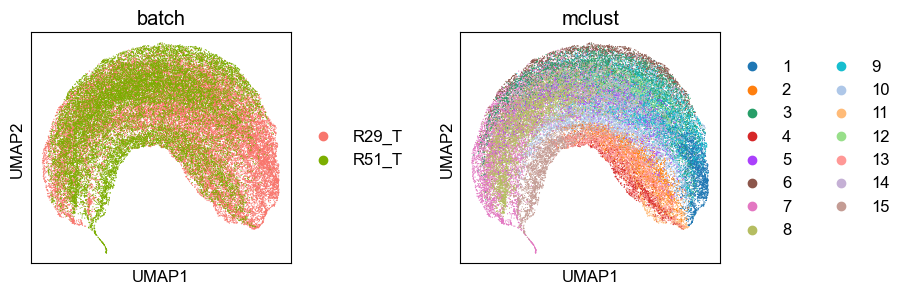

In [5]:
adata_concat.obs['mclust'] = adata_concat.obs['mclust'].astype(str)
sc.pp.neighbors(adata_concat, use_rep='SIMPLE', random_state=seed)
sc.tl.umap(adata_concat, random_state=seed)

section_color = ['#f8766d', '#7cae00']
section_color_dict = dict(zip(slice_ids, section_color))
adata_concat.uns['batch_colors'] = [section_color_dict[x] for x in adata_concat.obs.batch.cat.categories]

plt.rcParams['font.sans-serif'] = "Arial"
plt.rcParams["figure.figsize"] = (3, 3)
plt.rcParams['font.size'] = 12

sc.pl.umap(adata_concat, color=['batch','mclust'], ncols=3, wspace=0.5, show=False)
plt.show()
plt.close()

## 6. visualization

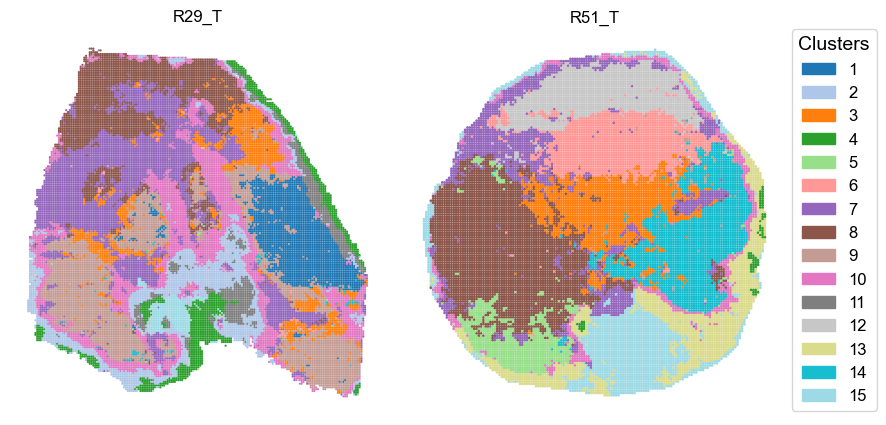

In [6]:
adata_list = []
for i,id in enumerate(slice_ids):
    adata_list.append(adata_concat[adata_concat.obs['batch'] == id])

import matplotlib.patches as mpatches
# spot_size = 175
spot_size = 1.2
title_size = 12

clusters_set = set(adata_list[0].obs['mclust'].astype(str)) \
               .union(set(adata_list[1].obs['mclust'].astype(str)))
all_clusters = sorted(clusters_set, key=lambda x: int(x) if x.isdigit() else x)
base_colors = plt.cm.get_cmap('tab20', len(all_clusters)).colors
palette = {cl: base_colors[i] for i, cl in enumerate(all_clusters)}

fig, ax = plt.subplots(1, len(slice_ids), figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for i in range(len(slice_ids)):
    _sc=sc.pl.spatial(adata_list[i], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[i], frameon=False,palette=palette,
                      spot_size=spot_size)
    _sc[0].set_title(slice_ids[i], size=title_size)
# 统一图例
handles = [mpatches.Patch(color=palette[cl], label=f"{cl}") for cl in all_clusters]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(0.9, 0.5),
           fontsize=12, title_fontsize=14,title="Clusters")
plt.show()


## 7.visualization of special cluster

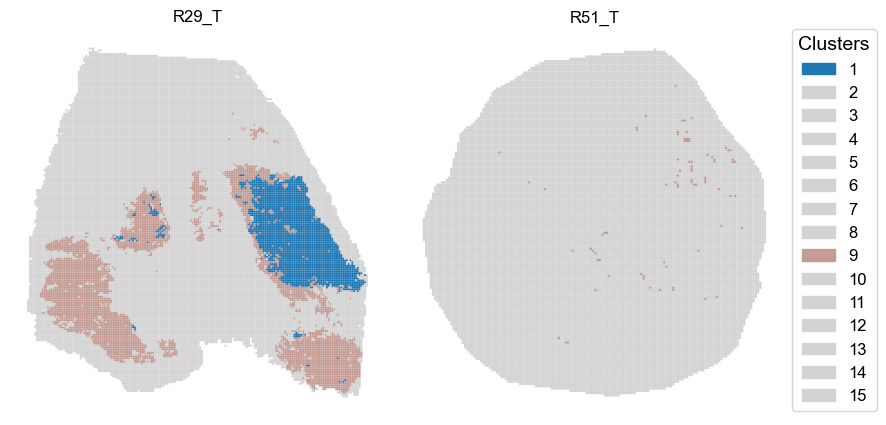

In [7]:
import matplotlib.patches as mpatches

spot_size = 1.2
title_size = 12

clusters_set = set(adata_list[0].obs['mclust'].astype(str)) \
               .union(set(adata_list[1].obs['mclust'].astype(str)))
all_clusters = sorted(clusters_set, key=lambda x: int(x) if x.isdigit() else x)

base_colors = plt.cm.get_cmap('tab20', len(all_clusters)).colors
original_palette = {cl: base_colors[i] for i, cl in enumerate(all_clusters)}

palette = {
    cl: original_palette[cl] if cl in ['9', '1'] else '#D3D3D3'
    for cl in all_clusters
}

fig, ax = plt.subplots(1, len(slice_ids),figsize=(10, 5),gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for i in range(len(slice_ids)):
    _sc = sc.pl.spatial(adata_list[i], img_key=None, color=['mclust'], title=[''], legend_loc=None,
                        legend_fontsize=12, show=False, ax=ax[i], frameon=False, palette=palette, spot_size=spot_size)
    _sc[0].set_title(slice_ids[i], size=title_size)

handles = [mpatches.Patch(color=palette[cl], label=f"{cl}") for cl in all_clusters]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(0.9, 0.5), fontsize=12, title_fontsize=14,title="Clusters")
plt.show()
